# Lab: Data Wrangling

In this exercise we will extract tabular data from an article published in an online scientific journal. We will touch on the following topics:

- Extraction of data from HTML pages
- Data cleanup using Pandas
- Data visualization
- CSV export
- FAIR data principles

## Extract data from a scientific paper

This will extract Table 1 from the scientific paper [_NMR determination of pKa values in α‐synuclein_](https://doi.org/10.1002/pro.556).
It is a nice study of the acid dissociation constants of amino acids inside a protein, measured using NMR spectroscopy.

The first extraction below is messy, so a bit of cleanup is needed.
Note that `pandas` requires that the `lxml` package is installed.
To run this, do the following:
1. Follow the link to the above paper, assuming you have full-text access
2. Save the page as `croke.html` and place it in this folder. The resulting `html` file may vary, depending on what browser (and probably year!) you're downloading. Your teacher may help you obtain a suitable version.
3. Run the cell below

In [37]:
%matplotlib inline
import matplotlib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


# Load HTML using Pandas. If on Colab, you must upload the HTML to your session.
df_original = pd.read_html("croke.html") #returns a list of df

### Task 0

What is the type of `df_original`? We want to focus on the "No salt" data set, so go ahead and extract that.

`df_original` is a list of Dataframes.


In [38]:
type(df_original) #list of df
df_no_salt = df_original[0]['No salt']
df_no_salt

,Site,pKa,n,Î´low,Î´high
0,Asp2,3.61 Â± 0.05,1.30 Â± 0.21,38.64 Â± 0.09,41.99 Â± 0.06
1,"Glu13cc Glu13, Glu46 and Glu105 titrate as a s...",4.21 Â± 0.06,0.90 Â± 0.08,33.11 Â± 0.08,36.79 Â± 0.08
2,Glu20,4.07 Â± 0.04,0.93 Â± 0.06,33.10 Â± 0.05,36.74 Â± 0.04
3,Glu28,4.20 Â± 0.06,0.96 Â± 0.09,33.16 Â± 0.08,36.92 Â± 0.08
4,Glu35dd The assignments for Glu35 and Glu110 a...,4.17Â±0.06,0.93 Â± 0.08,33.11 Â± 0.07,36.69 Â± 0.07
5,"Glu46cc Glu13, Glu46 and Glu105 titrate as a s...",4.21Â±0.06,0.90 Â± 0.08,33.11 Â± 0.08,36.79 Â± 0.08
6,His50,6.78 Â± 0.04,1.08 Â± 0.08,123.11 Â± 0.02,125.05 Â± 0.06
7,Glu57,4.20 Â± 0.05,0.94 Â± 0.08,33.10 Â± 0.07,36.87 Â± 0.07
8,Glu61,4.04 Â± 0.27,0.86 Â± 0.35,121.05 Â± 0.07,121.70 Â± 0.08
9,Glu83,4.35 Â± 0.05,1.07 Â± 0.10,33.14 Â± 0.06,36.71 Â± 0.07


### Task 1

The above table cannot be readily processed for various reasons. Firstly, the numbers are actually _strings_ and contain the unicode character `±`.
Secondly, values and errors are mixed.
Your task is now to cleanup the above table so that it looks something like this (we have only printed the first couple of rows here):

pKa   |  err |  resname | resnum
----- | ---- | -------- | -----------
3.61  | 0.05 | Asp      | 2
4.21  | 0.06 | Glu      | 13
...   | ...  | ...      | ...

In your report, document and motivate your code. Note how the residue name; error; and residue number have been separated to three individual columns.

#### Hints:
1. Do this in small steps!
1. This cleanup is mostly an exercise in how to use Pandas. There's plenty of online information about this and you may search for _"Delete pandas column"_ etc.
1. Try to run `df.pKa.str.split("±").str.get(0).astype(float)` in a cell. Figure out what each method is doing.
1. Columns can be assigned with `df.assign()` or dropped with `df.drop()`.
1. Some values in the `Site` column are suffixed by letters `c` and `d`. Use `str.replace()` to get rid of these.
1. Combined residue name and number can be split using [_regex_](https://en.wikipedia.org/wiki/Regular_expression), i.e. something like `str.split("([A-Za-z]+)(\d+)")`.

At first an empty dataframe was created (`df_final`) where all the cleaned-up columns are going to get assigned.

The first column to get assigned to the new Dataframe was the one containing the values of pKa that were obtained from the original Dataframe by splitting the pKa column and converting the pKa values from strings to floats.  

In [39]:
df_final = pd.DataFrame()

# pKa column

df_final = df_final.assign(pKa = df_no_salt.pKa.str.split("Â±").str.get(0).astype(float))
# the command gets the pKa values without the errors and converts them from
# strings to floats


The other part of the oringinal pKa column containing the errors got assigned to a new column "err" in the `df_final`

In [40]:
# error column
df_final = df_final.assign(err = df_no_salt.pKa.str.split("Â±").str.get(1).astype(float))


The original table contained some footnotes that are now goint to get removed using the function `str.replace()`.

In [41]:
resname_num = df_no_salt.Site.str.replace('cc', '')
resname_num = resname_num.str.replace('dd', '')

The residude column got split into the residued name and the number using the command `str.extract()` and  Regular Expressions (regex).

In [42]:
resname_num = resname_num.str.split(" ").str.get(0)

df_final[['resname', 'resnum']] = resname_num.str.extract(r"([A-Za-z]+)(\d+)")

One thing left to fix is the last value of the table, since it didn't match the pattern of the other residudes it got manually filled in.

In [43]:
#filling the missing resname with the original value from resname_num
df_final['resname'] = df_final['resname'].fillna('a-CO2-')
df_final['resnum'] = df_final['resnum'].fillna('')

display(df_final)

,pKa,err,resname,resnum
0,3.61,0.05,Asp,2
1,4.21,0.06,Glu,13
2,4.07,0.04,Glu,20
3,4.20,0.06,Glu,28
4,4.17,0.06,Glu,35
5,4.21,0.06,Glu,46
6,6.78,0.04,His,50
7,4.20,0.05,Glu,57
8,4.04,0.27,Glu,61
9,4.35,0.05,Glu,83


### Task 2

Export the above data to a `CSV` file. Motivate why or why not this is a good idea?

Importing the data to a CSV file adhers more to the FAIR principles than how the data was originally presented. 
The CSV format is the most common format for tabular data and is thus very established and interoperable.  

In [44]:
df_final.to_csv('out.csv')

### Task 3

The acid dissocitation constant of an isolated glutamic acid ("Glu") is p$K_a^0$=4.1.
As a function of residue number, plot the shift from this reference value for all glutamates in the above tabel.
_Hints:_ Use `matplotlib` and a `pandas` mask using _e.g._ `mask = df.resname == "Glu"`.
Your plot could look something like the following:

Text(0, 0.5, 'pKa')

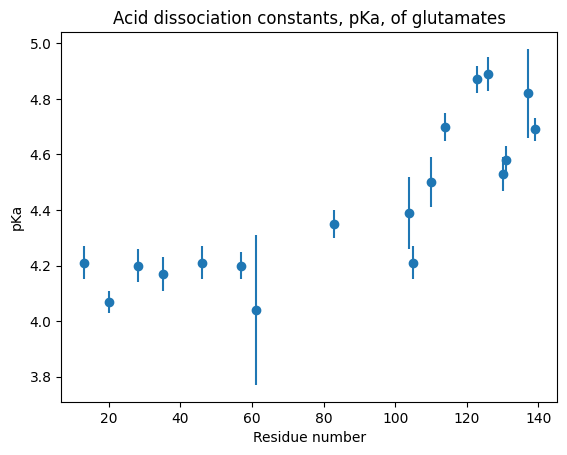

In [47]:
mask = df_final.resname == "Glu"

#creating a new dataframe with only the glutamates
df_glu = df_final[mask].copy()

df_glu['resnum'] = pd.to_numeric(df_glu['resnum']) #from string to numeric because it was giving problems with the xticks


# PLOT
figure, ax = plt.subplots()
 

#pKa
ax.scatter(df_glu[df_glu.columns[3]],df_glu[df_glu.columns[0]])
#errors
ax.vlines(df_glu[df_glu.columns[3]], df_glu[df_glu.columns[0]]-df_glu[df_glu.columns[1]], df_glu[df_glu.columns[0]]+df_glu[df_glu.columns[1]], linestyles='solid')

ax.set_xticks(np.arange(20, 160, step=20)) #so that it resembles the given graph

ax.set_title('Acid dissociation constants, pKa, of glutamates')
ax.set_xlabel('Residue number')
ax.set_ylabel('pKa')



## FAIR Principles 
How the workflow is presented in this notebook is an improvement regarding the FAIR data principles, especially in terms of Interoperability and Reusability. 

The original tabular data was presented in a HTML format which is is an improvement compared to PDFs because it's structured but it still requires some data wrangling to work with the data. 
After the work that was done in this notebook we end up with a workable CSV file, managing, in this way, to lower the barrier for future usage of the data.